In [84]:

# Lab6-Self-Balancing Binary Search Tree

import random
import math
import time
import matplotlib.pyplot as plt

# Fixed seed keeps the experiments reproducible.
RANDOM_SEED = 42
random.seed(RANDOM_SEED)

# Dataset sizes required by the lab.
DATASET_SIZES = [1000, 5000, 10000]

print("LAB 6: SELF-BALANCING BST")
print("-" * 45)
print("Random seed:", RANDOM_SEED)
print("Dataset sizes:", DATASET_SIZES)
print("Environment: Google Colab")
print("Initial setup completed.")


LAB 6: SELF-BALANCING BST
---------------------------------------------
Random seed: 42
Dataset sizes: [1000, 5000, 10000]
Environment: Google Colab
Initial setup completed.


In [85]:

# CORRECTED PLAIN BST IMPLEMENTATION

class BSTNode:
    def __init__(self, patient_id, patient_name):
        self.patient_id = patient_id
        self.patient_name = patient_name
        self.left = None
        self.right = None


class PlainBST:
    def __init__(self):
        self.root = None
        self.comparisons = 0

    def reset_comparisons(self):
        self.comparisons = 0

    # Insert a patient record
    def insert(self, patient_id, patient_name):
        new_node = BSTNode(patient_id, patient_name)

        if self.root is None:
            self.root = new_node
            return

        current = self.root

        while True:
            self.comparisons += 1

            if patient_id == current.patient_id:
                current.patient_name = patient_name
                return

            if patient_id < current.patient_id:
                if current.left is None:
                    current.left = new_node
                    return
                current = current.left
            else:
                if current.right is None:
                    current.right = new_node
                    return
                current = current.right

    # Search and return the patient name
    def search(self, patient_id):
        current = self.root

        while current is not None:
            self.comparisons += 1

            if patient_id == current.patient_id:
                return current.patient_name

            self.comparisons += 1

            if patient_id < current.patient_id:
                current = current.left
            else:
                current = current.right

        return None

    # Find the smallest node in a subtree
    def minimum_node(self, node):
        current = node

        while current.left is not None:
            current = current.left

        return current

    # Delete a patient record
    def delete(self, patient_id):
        parent = None
        current = self.root

        while current is not None and current.patient_id != patient_id:
            parent = current

            if patient_id < current.patient_id:
                current = current.left
            else:
                current = current.right

        if current is None:
            return False

        # Case 1: Node has two children
        if current.left is not None and current.right is not None:
            successor_parent = current
            successor = current.right

            while successor.left is not None:
                successor_parent = successor
                successor = successor.left

            current.patient_id = successor.patient_id
            current.patient_name = successor.patient_name

            parent = successor_parent
            current = successor

        # Case 2: Node has zero or one child
        if current.left is not None:
            child = current.left
        else:
            child = current.right

        if parent is None:
            self.root = child
        elif parent.left == current:
            parent.left = child
        else:
            parent.right = child

        return True

    # In-order traversal
    def inorder(self):
        result = []
        stack = []
        current = self.root

        while stack or current is not None:
            while current is not None:
                stack.append(current)
                current = current.left

            current = stack.pop()
            result.append(
                (current.patient_id, current.patient_name)
            )
            current = current.right

        return result

    # Calculate tree height
    def height(self):
        if self.root is None:
            return 0

        stack = [(self.root, 1)]
        maximum_height = 0

        while stack:
            node, level = stack.pop()
            maximum_height = max(maximum_height, level)

            if node.left is not None:
                stack.append((node.left, level + 1))

            if node.right is not None:
                stack.append((node.right, level + 1))

        return maximum_height

    # Display tree sideways
    def display(self):
        def show(node, level=0):
            if node is not None:
                show(node.right, level + 1)
                print("    " * level + str(node.patient_id))
                show(node.left, level + 1)

        if self.root is None:
            print("Tree is empty.")
        else:
            show(self.root)


In [86]:

test = PlainBST()

test.insert(1, "Patient 1")
test.insert(2, "Patient 2")
test.insert(3, "Patient 3")

print("Search:", test.search(1))
print("In-order:", test.inorder())
print("Height:", test.height())

print("Delete ID 2:", test.delete(2))
print("After deletion:", test.inorder())


Search: Patient 1
In-order: [(1, 'Patient 1'), (2, 'Patient 2'), (3, 'Patient 3')]
Height: 3
Delete ID 2: True
After deletion: [(1, 'Patient 1'), (3, 'Patient 3')]


In [87]:
# PART A: PLAIN BST TESTS

def test_plain_bst():
    print("PART A: PLAIN BST TEST")
    print("-" * 50)

    tree = PlainBST()

    # Sample sequence from the lab question.
    records = [
        (10, "Patient A"),
        (20, "Patient B"),
        (30, "Patient C"),
        (40, "Patient D"),
        (50, "Patient E"),
        (25, "Patient F")
    ]

    for patient_id, patient_name in records:
        tree.insert(patient_id, patient_name)

    print("\nTree structure:")
    tree.display()

    print("\nIn-order traversal:")
    print(tree.inorder())

    print("\nTree height:", tree.height())
    print("Insertion comparisons:", tree.comparisons)

    # Successful search.
    tree.reset_comparisons()
    result = tree.search(25)

    assert result == "Patient F"

    print("\nSearch for ID 25: PASSED")
    print("Search comparisons:", tree.comparisons)

    # Unsuccessful search.
    tree.reset_comparisons()
    result = tree.search(99)

    assert result is None

    print("Search for ID 99: PASSED")
    print("Search comparisons:", tree.comparisons)

    # Verify the sample traversal and height.
    expected_ids = [10, 20, 25, 30, 40, 50]
    actual_ids = [record[0] for record in tree.inorder()]

    assert actual_ids == expected_ids
    assert tree.height() == 5

    print("\nSample BST verification: PASSED")


def test_bst_deletion_cases():
    print("\nPART A: DELETION CASE TESTS")
    print("-" * 50)

    # Case 1: Delete a leaf node.
    tree1 = PlainBST()

    for key in [20, 10, 30]:
        tree1.insert(key, f"Patient {key}")

    assert tree1.delete(10) is True
    assert [x[0] for x in tree1.inorder()] == [20, 30]

    print("Case 1 - Leaf deletion: PASSED")

    # Case 2: Delete a node with one child.
    tree2 = PlainBST()

    for key in [20, 10, 30, 40]:
        tree2.insert(key, f"Patient {key}")

    assert tree2.delete(30) is True
    assert [x[0] for x in tree2.inorder()] == [10, 20, 40]

    print("Case 2 - One-child deletion: PASSED")

    # Case 3: Delete a node with two children.
    tree3 = PlainBST()

    for key in [20, 10, 30, 25, 40]:
        tree3.insert(key, f"Patient {key}")

    assert tree3.delete(20) is True
    assert [x[0] for x in tree3.inorder()] == [10, 25, 30, 40]

    print("Case 3 - Two-child deletion: PASSED")


def test_empty_bst():
    print("\nPART A: EMPTY TREE TEST")
    print("-" * 50)

    tree = PlainBST()

    assert tree.height() == 0
    assert tree.inorder() == []
    assert tree.search(10) is None
    assert tree.delete(10) is False

    print("Empty tree operations: PASSED")


# Run all Part A tests.
test_plain_bst()
test_bst_deletion_cases()
test_empty_bst()

PART A: PLAIN BST TEST
--------------------------------------------------

Tree structure:
                50
            40
        30
            25
    20
10

In-order traversal:
[(10, 'Patient A'), (20, 'Patient B'), (25, 'Patient F'), (30, 'Patient C'), (40, 'Patient D'), (50, 'Patient E')]

Tree height: 5
Insertion comparisons: 13

Search for ID 25: PASSED
Search comparisons: 7
Search for ID 99: PASSED
Search comparisons: 10

Sample BST verification: PASSED

PART A: DELETION CASE TESTS
--------------------------------------------------
Case 1 - Leaf deletion: PASSED
Case 2 - One-child deletion: PASSED
Case 3 - Two-child deletion: PASSED

PART A: EMPTY TREE TEST
--------------------------------------------------
Empty tree operations: PASSED


In [88]:

class AVLNode:
    def __init__(self, patient_id, patient_name):
        self.patient_id = patient_id
        self.patient_name = patient_name
        self.left = None
        self.right = None
        self.height = 1


class AVLTree:
    def __init__(self):
        self.root = None
        self.comparisons = 0
        self.rotations = 0

    def reset_comparisons(self):
        self.comparisons = 0

    def reset_rotations(self):
        self.rotations = 0

    # A missing node has height zero.
    def node_height(self, node):
        if node is None:
            return 0
        return node.height

    # Balance factor = left height - right height.
    def balance_factor(self, node):
        if node is None:
            return 0

        return (
            self.node_height(node.left)
            - self.node_height(node.right)
        )

    def update_height(self, node):
        node.height = 1 + max(
            self.node_height(node.left),
            self.node_height(node.right)
        )


print("AVL node structure and basic methods defined.")


AVL node structure and basic methods defined.


In [89]:

# COMPLETE AVL TREE IMPLEMENTATION

class AVLNode:
    def __init__(self, patient_id, patient_name):
        self.patient_id = patient_id
        self.patient_name = patient_name
        self.left = None
        self.right = None
        self.height = 1


class AVLTree:
    def __init__(self):
        self.root = None
        self.comparisons = 0
        self.rotations = 0

    def reset_comparisons(self):
        self.comparisons = 0

    def reset_rotations(self):
        self.rotations = 0

    def node_height(self, node):
        if node is None:
            return 0
        return node.height

    def balance_factor(self, node):
        if node is None:
            return 0
        return self.node_height(node.left) - self.node_height(node.right)

    def update_height(self, node):
        node.height = 1 + max(
            self.node_height(node.left),
            self.node_height(node.right)
        )

    # Right rotation (used for LL and part of RL/LR cases)
    def rotate_right(self, y):
        x = y.left
        subtree = x.right

        x.right = y
        y.left = subtree

        self.update_height(y)
        self.update_height(x)

        self.rotations += 1
        return x

    # Left rotation (used for RR and part of LR/RL cases)
    def rotate_left(self, x):
        y = x.right
        subtree = y.left

        y.left = x
        x.right = subtree

        self.update_height(x)
        self.update_height(y)

        self.rotations += 1
        return y

    # Restore AVL balance after insertion or deletion
    def rebalance(self, node):
        if node is None:
            return None

        self.update_height(node)
        balance = self.balance_factor(node)

        # Left-heavy subtree
        if balance > 1:
            if self.balance_factor(node.left) < 0:
                # LR case
                node.left = self.rotate_left(node.left)

            # LL case
            return self.rotate_right(node)

        # Right-heavy subtree
        if balance < -1:
            if self.balance_factor(node.right) > 0:
                # RL case
                node.right = self.rotate_right(node.right)

            # RR case
            return self.rotate_left(node)

        return node

    # Insert a patient record
    def insert(self, patient_id, patient_name):
        self.root = self._insert(
            self.root, patient_id, patient_name
        )

    def _insert(self, node, patient_id, patient_name):
        if node is None:
            return AVLNode(patient_id, patient_name)

        self.comparisons += 1

        if patient_id < node.patient_id:
            node.left = self._insert(
                node.left, patient_id, patient_name
            )
        elif patient_id > node.patient_id:
            node.right = self._insert(
                node.right, patient_id, patient_name
            )
        else:
            node.patient_name = patient_name
            return node

        return self.rebalance(node)

    # Search for a patient record
    def search(self, patient_id):
        current = self.root

        while current is not None:
            self.comparisons += 1

            if patient_id == current.patient_id:
                return current.patient_name

            self.comparisons += 1

            if patient_id < current.patient_id:
                current = current.left
            else:
                current = current.right

        return None

    # Find the smallest node in a subtree
    def minimum_node(self, node):
        current = node

        while current.left is not None:
            current = current.left

        return current

    # Delete a patient record
    def delete(self, patient_id):
        self.root, deleted = self._delete(
            self.root, patient_id
        )
        return deleted

    def _delete(self, node, patient_id):
        if node is None:
            return None, False

        deleted = False

        if patient_id < node.patient_id:
            node.left, deleted = self._delete(
                node.left, patient_id
            )

        elif patient_id > node.patient_id:
            node.right, deleted = self._delete(
                node.right, patient_id
            )

        else:
            deleted = True

            # Case 1: No child or only right child
            if node.left is None:
                return node.right, True

            # Case 2: Only left child
            if node.right is None:
                return node.left, True

            # Case 3: Two children
            successor = self.minimum_node(node.right)

            node.patient_id = successor.patient_id
            node.patient_name = successor.patient_name

            node.right, _ = self._delete(
                node.right, successor.patient_id
            )

        # Rebalance only if a deletion actually occurred
        if not deleted:
            return node, False

        return self.rebalance(node), True

    # In-order traversal
    def inorder(self):
        result = []
        stack = []
        current = self.root

        while stack or current is not None:
            while current is not None:
                stack.append(current)
                current = current.left

            current = stack.pop()
            result.append(
                (current.patient_id, current.patient_name)
            )
            current = current.right

        return result

    # Height of the complete tree
    def height(self):
        return self.node_height(self.root)

    # Verify every node's balance factor and stored height
    def is_balanced(self):
        def check(node):
            if node is None:
                return True, 0

            left_valid, left_height = check(node.left)
            right_valid, right_height = check(node.right)

            actual_height = 1 + max(
                left_height, right_height
            )

            valid_balance = abs(
                left_height - right_height
            ) <= 1

            valid_height = node.height == actual_height

            return (
                left_valid and right_valid
                and valid_balance and valid_height,
                actual_height
            )

        valid, _ = check(self.root)
        return valid

    # Verify the Binary Search Tree ordering property
    def is_bst(self):
        def check(node, lower, upper):
            if node is None:
                return True

            if lower is not None and node.patient_id <= lower:
                return False

            if upper is not None and node.patient_id >= upper:
                return False

            return (
                check(node.left, lower, node.patient_id)
                and check(node.right, node.patient_id, upper)
            )

        return check(self.root, None, None)

    # Display the tree sideways
    def display(self):
        def show(node, level=0):
            if node is not None:
                show(node.right, level + 1)
                print(
                    "    " * level
                    + f"{node.patient_id} ({node.height})"
                )
                show(node.left, level + 1)

        if self.root is None:
            print("Tree is empty.")
        else:
            show(self.root)


In [90]:

#AVL ROTATION AND OPERATION TESTS

def test_rotation_case(case_name, values, expected_root):
    tree = AVLTree()

    for value in values:
        tree.insert(value, f"Patient {value}")

    print(f"\n{case_name} Rotation")
    print("Inserted values:", values)
    print("Root after balancing:", tree.root.patient_id)
    print("Height:", tree.height())
    print("Rotations:", tree.rotations)

    assert tree.root.patient_id == expected_root
    assert tree.is_balanced()
    assert tree.is_bst()

    print("AVL checks: PASSED")


# Test all four rotation cases
test_rotation_case("LL", [30, 20, 10], 20)
test_rotation_case("RR", [10, 20, 30], 20)
test_rotation_case("LR", [30, 10, 20], 20)
test_rotation_case("RL", [10, 30, 20], 20)


# Test a larger AVL tree
def test_avl_operations():
    tree = AVLTree()

    values = [10, 20, 30, 40, 50, 25]

    for value in values:
        tree.insert(value, f"Patient {value}")

    print("\nAVL Tree after insertion:")
    tree.display()

    print("\nIn-order traversal:")
    print(tree.inorder())

    print("\nTree height:", tree.height())
    print("Total rotations:", tree.rotations)

    assert tree.inorder() == [
        (10, "Patient 10"),
        (20, "Patient 20"),
        (25, "Patient 25"),
        (30, "Patient 30"),
        (40, "Patient 40"),
        (50, "Patient 50")
    ]

    assert tree.is_balanced()
    assert tree.is_bst()

    print("\nSearch for ID 25:", tree.search(25))
    print("Search for ID 99:", tree.search(99))

    # Test deletion of a leaf, one-child and two-child node
    deletion_tree = AVLTree()

    for value in [20, 10, 30, 25, 40, 5, 15]:
        deletion_tree.insert(value, f"Patient {value}")

    for value in [5, 25, 20]:
        result = deletion_tree.delete(value)

        print(f"\nDeleting ID {value}: {result}")
        print("Current in-order:", deletion_tree.inorder())

        assert result is True
        assert deletion_tree.is_balanced()
        assert deletion_tree.is_bst()

    # Check deletion of a missing ID
    assert deletion_tree.delete(999) is False

    print("\nAVL insertion, search and deletion tests PASSED.")


test_avl_operations()



LL Rotation
Inserted values: [30, 20, 10]
Root after balancing: 20
Height: 2
Rotations: 1
AVL checks: PASSED

RR Rotation
Inserted values: [10, 20, 30]
Root after balancing: 20
Height: 2
Rotations: 1
AVL checks: PASSED

LR Rotation
Inserted values: [30, 10, 20]
Root after balancing: 20
Height: 2
Rotations: 2
AVL checks: PASSED

RL Rotation
Inserted values: [10, 30, 20]
Root after balancing: 20
Height: 2
Rotations: 2
AVL checks: PASSED

AVL Tree after insertion:
        50 (1)
    40 (2)
30 (3)
        25 (1)
    20 (2)
        10 (1)

In-order traversal:
[(10, 'Patient 10'), (20, 'Patient 20'), (25, 'Patient 25'), (30, 'Patient 30'), (40, 'Patient 40'), (50, 'Patient 50')]

Tree height: 3
Total rotations: 4

Search for ID 25: Patient 25
Search for ID 99: None

Deleting ID 5: True
Current in-order: [(10, 'Patient 10'), (15, 'Patient 15'), (20, 'Patient 20'), (25, 'Patient 25'), (30, 'Patient 30'), (40, 'Patient 40')]

Deleting ID 25: True
Current in-order: [(10, 'Patient 10'), (15, 'Pa

In [91]:

#WORKLOAD GENERATION

def generate_workloads(n, seed):
    rng = random.Random(seed)

    # Dataset 1: Sequential IDs
    sequential = list(range(1, n + 1))

    # Dataset 2: Random permutation
    random_data = sequential.copy()
    rng.shuffle(random_data)

    # Dataset 3: Nearly sorted
    nearly_sorted = sequential.copy()

    # Select approximately 5% of positions
    # and swap them in pairs.
    number_of_positions = max(2, round(0.05 * n))
    selected_positions = rng.sample(
        range(n), number_of_positions
    )

    for i in range(0, len(selected_positions) - 1, 2):
        first = selected_positions[i]
        second = selected_positions[i + 1]

        nearly_sorted[first], nearly_sorted[second] = (
            nearly_sorted[second],
            nearly_sorted[first]
        )

    return {
        "Sequential": sequential,
        "Random": random_data,
        "Nearly Sorted": nearly_sorted
    }


# Verify workload generation
for size in DATASET_SIZES:
    datasets = generate_workloads(size, RANDOM_SEED + size)

    print(f"\nDataset size: {size}")

    for dataset_name, data in datasets.items():
        print(
            dataset_name,
            "| Number of IDs:", len(data),
            "| First 10:", data[:10],
            "| Unique IDs:", len(set(data))
        )

        assert len(data) == size
        assert set(data) == set(range(1, size + 1))

print("\nAll workload generation checks PASSED.")



Dataset size: 1000
Sequential | Number of IDs: 1000 | First 10: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10] | Unique IDs: 1000
Random | Number of IDs: 1000 | First 10: [49, 547, 833, 853, 257, 542, 425, 421, 19, 244] | Unique IDs: 1000
Nearly Sorted | Number of IDs: 1000 | First 10: [1, 216, 3, 4, 876, 6, 7, 8, 9, 10] | Unique IDs: 1000

Dataset size: 5000
Sequential | Number of IDs: 5000 | First 10: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10] | Unique IDs: 5000
Random | Number of IDs: 5000 | First 10: [2365, 434, 3850, 3049, 668, 2169, 1768, 1170, 2476, 1452] | Unique IDs: 5000
Nearly Sorted | Number of IDs: 5000 | First 10: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10] | Unique IDs: 5000

Dataset size: 10000
Sequential | Number of IDs: 10000 | First 10: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10] | Unique IDs: 10000
Random | Number of IDs: 10000 | First 10: [721, 7596, 4152, 580, 75, 70, 1213, 935, 6731, 2810] | Unique IDs: 10000
Nearly Sorted | Number of IDs: 10000 | First 10: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10] | Unique IDs: 10000

A

In [92]:
# EXPERIMENT RUNNER

def run_tree_experiment(tree_type, insertion_order,
                        search_ids, deletion_ids):

    tree = tree_type()

    # Create patient records.
    records = [
        (patient_id, f"Patient {patient_id}")
        for patient_id in insertion_order
    ]

    # -----------------------------------------
    # 1. INSERTION TIME
    # -----------------------------------------

    start_time = time.perf_counter()

    for patient_id, patient_name in records:
        tree.insert(patient_id, patient_name)

    insertion_time = time.perf_counter() - start_time

    # Record height after insertion.
    height_after_insert = tree.height()

    # Record rotations for AVL.
    rotations = getattr(tree, "rotations", 0)

    # -----------------------------------------
    # 2. SUCCESSFUL SEARCH COMPARISONS
    # -----------------------------------------

    total_comparisons = 0

    for patient_id in search_ids:

        tree.reset_comparisons()

        result = tree.search(patient_id)

        expected_result = f"Patient {patient_id}"

        if result != expected_result:
            raise AssertionError(
                f"Search failed in {tree_type.__name__} "
                f"for Patient ID {patient_id}. "
                f"Expected: {expected_result}, "
                f"Received: {result}"
            )

        total_comparisons += tree.comparisons

    average_comparisons = (
        total_comparisons / len(search_ids)
        if len(search_ids) > 0
        else 0
    )

    # -----------------------------------------
    # 3. DELETE 20% OF THE RECORDS
    # -----------------------------------------

    for patient_id in deletion_ids:

        deleted = tree.delete(patient_id)

        if deleted is not True:
            raise AssertionError(
                f"Deletion failed in {tree_type.__name__} "
                f"for Patient ID {patient_id}"
            )

    height_after_deletion = tree.height()

    # -----------------------------------------
    # 4. VALIDATE THE REMAINING TREE
    # -----------------------------------------

    if isinstance(tree, AVLTree):

        assert tree.is_balanced(), (
            "AVL balance validation failed."
        )

        assert tree.is_bst(), (
            "AVL BST property validation failed."
        )

    # Return all measured results.
    return {
        "height_after_insert": height_after_insert,
        "insertion_seconds": insertion_time,
        "rotations": rotations,
        "avg_search_comparisons": average_comparisons,
        "height_after_delete": height_after_deletion
    }


# =============================================
# RUN ALL REQUIRED EXPERIMENTS
# =============================================

results = []

TREE_TYPES = {
    "Plain BST": PlainBST,
    "AVL": AVLTree
}

for n in DATASET_SIZES:

    datasets = generate_workloads(
        n,
        RANDOM_SEED + n
    )

    for dataset_name, insertion_order in datasets.items():

        # Generate fixed search and deletion samples.
        sample_rng = random.Random(
            RANDOM_SEED + n * 10 + len(dataset_name)
        )

        search_ids = sample_rng.sample(
            range(1, n + 1),
            1000
        )

        deletion_ids = sample_rng.sample(
            range(1, n + 1),
            round(0.20 * n)
        )

        print(
            f"\nRunning N={n}, Dataset={dataset_name}"
        )

        for tree_name, tree_class in TREE_TYPES.items():

            print(f"\nTesting {tree_name}...")

            metrics = run_tree_experiment(
                tree_class,
                insertion_order,
                search_ids,
                deletion_ids
            )

            result_row = {
                "Dataset": dataset_name,
                "N": n,
                "Tree": tree_name,

                "Height After Insert":
                    metrics["height_after_insert"],

                "PDF floor(log2 N)":
                    math.floor(math.log2(n)),

                "Insertion Time (seconds)":
                    metrics["insertion_seconds"],

                "Rotations":
                    metrics["rotations"],

                "Average Search Comparisons":
                    metrics["avg_search_comparisons"],

                "Height After 20% Deletion":
                    metrics["height_after_delete"]
            }

            results.append(result_row)

            print(
                tree_name,
                "| Height:", metrics["height_after_insert"],
                "| Time:", round(
                    metrics["insertion_seconds"], 5
                ),
                "| Rotations:", metrics["rotations"],
                "| Avg comparisons:", round(
                    metrics["avg_search_comparisons"], 3
                ),
                "| Height after deletion:",
                metrics["height_after_delete"]
            )


print("\n" + "=" * 60)
print("ALL REQUIRED BST AND AVL EXPERIMENTS COMPLETED.")
print("Total experiment records:", len(results))
print("=" * 60)


Running N=1000, Dataset=Sequential

Testing Plain BST...
Plain BST | Height: 1000 | Time: 0.06161 | Rotations: 0 | Avg comparisons: 1000.0 | Height after deletion: 800

Testing AVL...
AVL | Height: 10 | Time: 0.00739 | Rotations: 990 | Avg comparisons: 16.974 | Height after deletion: 10

Running N=1000, Dataset=Random

Testing Plain BST...
Plain BST | Height: 23 | Time: 0.00171 | Rotations: 0 | Avg comparisons: 23.804 | Height after deletion: 20

Testing AVL...
AVL | Height: 12 | Time: 0.00663 | Rotations: 700 | Avg comparisons: 17.438 | Height after deletion: 11

Running N=1000, Dataset=Nearly Sorted

Testing Plain BST...
Plain BST | Height: 103 | Time: 0.00495 | Rotations: 0 | Avg comparisons: 78.53 | Height after deletion: 81

Testing AVL...
AVL | Height: 11 | Time: 0.00724 | Rotations: 1170 | Avg comparisons: 17.336 | Height after deletion: 11

Running N=5000, Dataset=Sequential

Testing Plain BST...
Plain BST | Height: 5000 | Time: 1.50483 | Rotations: 0 | Avg comparisons: 5060.3

In [93]:

#RESULTS TABLE AND CSV EXPORT

import csv

columns = [
    "Dataset",
    "N",
    "Tree",
    "Height After Insert",
    "PDF floor(log2 N)",
    "Insertion Time (seconds)",
    "Rotations",
    "Average Search Comparisons",
    "Height After 20% Deletion"
]

print("\nFINAL COMPARISON TABLE")
print("=" * 145)

print(" | ".join(columns))
print("-" * 145)

for row in results:
    print(
        f'{row["Dataset"]} | '
        f'{row["N"]} | '
        f'{row["Tree"]} | '
        f'{row["Height After Insert"]} | '
        f'{row["PDF floor(log2 N)"]} | '
        f'{row["Insertion Time (seconds)"]:.5f} | '
        f'{row["Rotations"]} | '
        f'{row["Average Search Comparisons"]:.3f} | '
        f'{row["Height After 20% Deletion"]}'
    )

# Save the complete table as CSV
csv_filename = "/content/lab6_bst_avl_results.csv"

with open(csv_filename, "w", newline="") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=columns
    )
    writer.writeheader()
    writer.writerows(results)

print("\nCSV file saved:", csv_filename)



FINAL COMPARISON TABLE
Dataset | N | Tree | Height After Insert | PDF floor(log2 N) | Insertion Time (seconds) | Rotations | Average Search Comparisons | Height After 20% Deletion
-------------------------------------------------------------------------------------------------------------------------------------------------
Sequential | 1000 | Plain BST | 1000 | 9 | 0.06161 | 0 | 1000.000 | 800
Sequential | 1000 | AVL | 10 | 9 | 0.00739 | 990 | 16.974 | 10
Random | 1000 | Plain BST | 23 | 9 | 0.00171 | 0 | 23.804 | 20
Random | 1000 | AVL | 12 | 9 | 0.00663 | 700 | 17.438 | 11
Nearly Sorted | 1000 | Plain BST | 103 | 9 | 0.00495 | 0 | 78.530 | 81
Nearly Sorted | 1000 | AVL | 11 | 9 | 0.00724 | 1170 | 17.336 | 11
Sequential | 5000 | Plain BST | 5000 | 12 | 1.50483 | 0 | 5060.364 | 4000
Sequential | 5000 | AVL | 13 | 12 | 0.05649 | 4987 | 21.772 | 13
Random | 5000 | Plain BST | 29 | 12 | 0.01069 | 0 | 28.666 | 27
Random | 5000 | AVL | 14 | 12 | 0.04085 | 3552 | 22.078 | 14
Nearly Sorted 

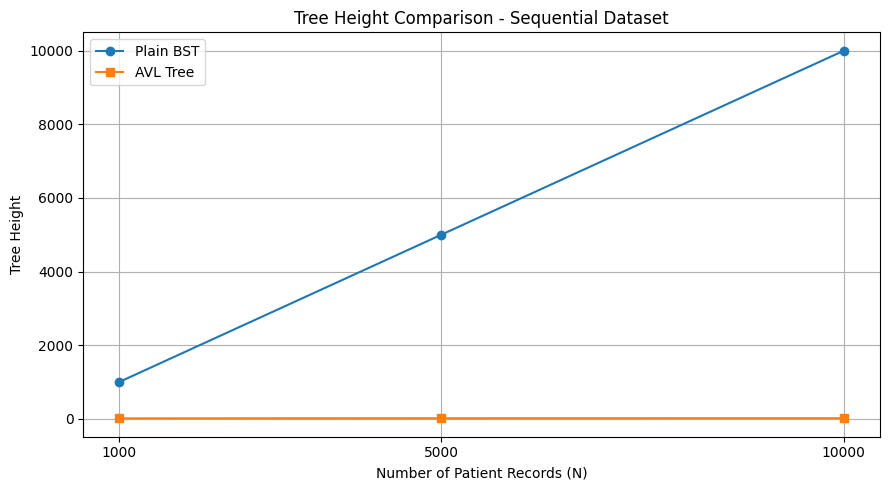

Graph saved successfully.


In [94]:

#GRAPH - SEQUENTIAL DATASET

sequential_results = [
    row for row in results
    if row["Dataset"] == "Sequential"
]

bst_results = sorted(
    [
        row for row in sequential_results
        if row["Tree"] == "Plain BST"
    ],
    key=lambda row: row["N"]
)

avl_results = sorted(
    [
        row for row in sequential_results
        if row["Tree"] == "AVL"
    ],
    key=lambda row: row["N"]
)

sizes = [row["N"] for row in bst_results]

bst_heights = [
    row["Height After Insert"] for row in bst_results
]

avl_heights = [
    row["Height After Insert"] for row in avl_results
]

plt.figure(figsize=(9, 5))

plt.plot(
    sizes, bst_heights,
    marker="o",
    label="Plain BST"
)

plt.plot(
    sizes, avl_heights,
    marker="s",
    label="AVL Tree"
)

plt.xlabel("Number of Patient Records (N)")
plt.ylabel("Tree Height")
plt.title("Tree Height Comparison - Sequential Dataset")

plt.xticks(sizes)
plt.grid(True)
plt.legend()
plt.tight_layout()

plt.savefig(
    "/content/lab6_sequential_height_comparison.png",
    dpi=300
)

plt.show()

print("Graph saved successfully.")


In [95]:
#RED-BLACK TREE IMPLEMENTATION

class RBNode:
    def __init__(self, key, name):
        self.key = key
        self.name = name
        self.color = "RED"
        self.left = None
        self.right = None
        self.parent = None


class RedBlackTree:
    def __init__(self):
        self.root = None

    def rotate_left(self, x):
        y = x.right
        x.right = y.left

        if y.left is not None:
            y.left.parent = x

        y.parent = x.parent

        if x.parent is None:
            self.root = y
        elif x == x.parent.left:
            x.parent.left = y
        else:
            x.parent.right = y

        y.left = x
        x.parent = y

    def rotate_right(self, y):
        x = y.left
        y.left = x.right

        if x.right is not None:
            x.right.parent = y

        x.parent = y.parent

        if y.parent is None:
            self.root = x
        elif y == y.parent.right:
            y.parent.right = x
        else:
            y.parent.left = x

        x.right = y
        y.parent = x

    def insert(self, key, name):
        new_node = RBNode(key, name)
        parent = None
        current = self.root

        # Ordinary BST insertion
        while current is not None:
            parent = current

            if key < current.key:
                current = current.left
            elif key > current.key:
                current = current.right
            else:
                current.name = name
                return

        new_node.parent = parent

        if parent is None:
            self.root = new_node
        elif key < parent.key:
            parent.left = new_node
        else:
            parent.right = new_node

        self.fix_insert(new_node)

    def fix_insert(self, node):
        while (
            node != self.root
            and node.parent.color == "RED"
        ):
            parent = node.parent
            grandparent = parent.parent

            if parent == grandparent.left:
                uncle = grandparent.right

                # Case 1: Red uncle - recolour
                if uncle is not None and uncle.color == "RED":
                    parent.color = "BLACK"
                    uncle.color = "BLACK"
                    grandparent.color = "RED"
                    node = grandparent

                else:
                    # Case 2: Inner child - rotate parent
                    if node == parent.right:
                        node = parent
                        self.rotate_left(node)
                        parent = node.parent
                        grandparent = parent.parent

                    # Case 3: Outer child - rotate grandparent
                    parent.color = "BLACK"
                    grandparent.color = "RED"
                    self.rotate_right(grandparent)

            else:
                uncle = grandparent.left

                # Mirror Case 1
                if uncle is not None and uncle.color == "RED":
                    parent.color = "BLACK"
                    uncle.color = "BLACK"
                    grandparent.color = "RED"
                    node = grandparent

                else:
                    # Mirror Case 2
                    if node == parent.left:
                        node = parent
                        self.rotate_right(node)
                        parent = node.parent
                        grandparent = parent.parent

                    # Mirror Case 3
                    parent.color = "BLACK"
                    grandparent.color = "RED"
                    self.rotate_left(grandparent)

        self.root.color = "BLACK"

    def search(self, key):
        current = self.root

        while current is not None:
            if key == current.key:
                return current.name
            elif key < current.key:
                current = current.left
            else:
                current = current.right

        return None

    def inorder(self):
        result = []
        stack = []
        current = self.root

        while stack or current is not None:
            while current is not None:
                stack.append(current)
                current = current.left

            current = stack.pop()
            result.append((current.key, current.name))
            current = current.right

        return result

    def height(self):
        def calculate(node):
            if node is None:
                return 0

            return 1 + max(
                calculate(node.left),
                calculate(node.right)
            )

        return calculate(self.root)

    # Check BST ordering and Red-Black properties
    def is_valid(self):
        if self.root is None:
            return True

        if self.root.color != "BLACK":
            return False

        def check(node, lower, upper):
            if node is None:
                return True, 1

            if lower is not None and node.key <= lower:
                return False, 0

            if upper is not None and node.key >= upper:
                return False, 0

            if node.color == "RED":
                if node.left is not None and node.left.color == "RED":
                    return False, 0
                if node.right is not None and node.right.color == "RED":
                    return False, 0

            left_valid, left_black_height = check(
                node.left, lower, node.key
            )

            right_valid, right_black_height = check(
                node.right, node.key, upper
            )

            if not left_valid or not right_valid:
                return False, 0

            if left_black_height != right_black_height:
                return False, 0

            black_count = (
                left_black_height
                + (1 if node.color == "BLACK" else 0)
            )

            return True, black_count

        valid, _ = check(self.root, None, None)
        return valid


# Test Red-Black Tree
rb_tree = RedBlackTree()

for value in [10, 20, 30, 15, 25, 5, 1, 8]:
    rb_tree.insert(value, f"Patient {value}")

print("Red-Black Tree in-order:")
print(rb_tree.inorder())

print("\nTree height:", rb_tree.height())
print("Search for 25:", rb_tree.search(25))
print("Search for 99:", rb_tree.search(99))
print("Red-Black properties valid:", rb_tree.is_valid())

assert rb_tree.is_valid()
assert [item[0] for item in rb_tree.inorder()] == [
    1, 5, 8, 10, 15, 20, 25, 30
]

print("\nRed-Black Tree test PASSED.")


Red-Black Tree in-order:
[(1, 'Patient 1'), (5, 'Patient 5'), (8, 'Patient 8'), (10, 'Patient 10'), (15, 'Patient 15'), (20, 'Patient 20'), (25, 'Patient 25'), (30, 'Patient 30')]

Tree height: 4
Search for 25: Patient 25
Search for 99: None
Red-Black properties valid: True

Red-Black Tree test PASSED.


In [96]:

#TREAP IMPLEMENTATION

class TreapNode:
    def __init__(self, key, name, priority):
        self.key = key
        self.name = name
        self.priority = priority
        self.left = None
        self.right = None


class Treap:
    def __init__(self, seed=42):
        self.root = None
        self.rng = random.Random(seed)

    def rotate_right(self, y):
        x = y.left
        y.left = x.right
        x.right = y
        return x

    def rotate_left(self, x):
        y = x.right
        x.right = y.left
        y.left = x
        return y

    def insert(self, key, name):
        priority = self.rng.random()
        self.root = self._insert(
            self.root, key, name, priority
        )

    def _insert(self, node, key, name, priority):
        if node is None:
            return TreapNode(key, name, priority)

        if key < node.key:
            node.left = self._insert(
                node.left, key, name, priority
            )

            if node.left.priority < node.priority:
                node = self.rotate_right(node)

        elif key > node.key:
            node.right = self._insert(
                node.right, key, name, priority
            )

            if node.right.priority < node.priority:
                node = self.rotate_left(node)

        else:
            node.name = name

        return node

    def search(self, key):
        current = self.root

        while current is not None:
            if key == current.key:
                return current.name
            elif key < current.key:
                current = current.left
            else:
                current = current.right

        return None

    def merge(self, left, right):
        if left is None:
            return right

        if right is None:
            return left

        if left.priority < right.priority:
            left.right = self.merge(left.right, right)
            return left

        right.left = self.merge(left, right.left)
        return right

    def delete(self, key):
        self.root, deleted = self._delete(self.root, key)
        return deleted

    def _delete(self, node, key):
        if node is None:
            return None, False

        if key < node.key:
            node.left, deleted = self._delete(node.left, key)
            return node, deleted

        if key > node.key:
            node.right, deleted = self._delete(node.right, key)
            return node, deleted

        # Replace the deleted node with a merged subtree
        return self.merge(node.left, node.right), True

    def inorder(self):
        result = []
        stack = []
        current = self.root

        while stack or current is not None:
            while current is not None:
                stack.append(current)
                current = current.left

            current = stack.pop()
            result.append((current.key, current.name))
            current = current.right

        return result

    def height(self):
        def calculate(node):
            if node is None:
                return 0

            return 1 + max(
                calculate(node.left),
                calculate(node.right)
            )

        return calculate(self.root)

    def is_valid(self):
        def check(node, lower, upper):
            if node is None:
                return True

            if lower is not None and node.key <= lower:
                return False

            if upper is not None and node.key >= upper:
                return False

            if node.left is not None:
                if node.left.priority < node.priority:
                    return False

            if node.right is not None:
                if node.right.priority < node.priority:
                    return False

            return (
                check(node.left, lower, node.key)
                and check(node.right, node.key, upper)
            )

        return check(self.root, None, None)


# Test Treap
treap = Treap(seed=RANDOM_SEED)

for value in [10, 20, 30, 15, 25, 5, 1, 8]:
    treap.insert(value, f"Patient {value}")

print("Treap in-order:")
print(treap.inorder())

print("\nTree height:", treap.height())
print("Search for 25:", treap.search(25))
print("Search for 99:", treap.search(99))
print("Treap properties valid:", treap.is_valid())

assert treap.is_valid()

assert [item[0] for item in treap.inorder()] == [
    1, 5, 8, 10, 15, 20, 25, 30
]

print("\nTreap test PASSED.")

# Test deletion
assert treap.delete(20) is True
assert treap.delete(999) is False
assert treap.is_valid()

print("Treap deletion test PASSED.")
print("After deletion:", treap.inorder())


Treap in-order:
[(1, 'Patient 1'), (5, 'Patient 5'), (8, 'Patient 8'), (10, 'Patient 10'), (15, 'Patient 15'), (20, 'Patient 20'), (25, 'Patient 25'), (30, 'Patient 30')]

Tree height: 4
Search for 25: Patient 25
Search for 99: None
Treap properties valid: True

Treap test PASSED.
Treap deletion test PASSED.
After deletion: [(1, 'Patient 1'), (5, 'Patient 5'), (8, 'Patient 8'), (10, 'Patient 10'), (15, 'Patient 15'), (25, 'Patient 25'), (30, 'Patient 30')]


In [97]:

# SECTION 13: SPLAY TREE IMPLEMENTATION

class SplayNode:
    def __init__(self, key, name):
        self.key = key
        self.name = name
        self.left = None
        self.right = None


class SplayTree:
    def __init__(self):
        self.root = None

    def rotate_right(self, x):
        y = x.left
        x.left = y.right
        y.right = x
        return y

    def rotate_left(self, x):
        y = x.right
        x.right = y.left
        y.left = x
        return y

    def splay(self, root, key):
        if root is None or root.key == key:
            return root

        # Key lies in the left subtree
        if key < root.key:
            if root.left is None:
                return root

            # Zig-Zig
            if key < root.left.key:
                root.left.left = self.splay(
                    root.left.left, key
                )
                root = self.rotate_right(root)

            # Zig-Zag
            elif key > root.left.key:
                root.left.right = self.splay(
                    root.left.right, key
                )

                if root.left.right is not None:
                    root.left = self.rotate_left(root.left)

            if root.left is None:
                return root

            return self.rotate_right(root)

        # Key lies in the right subtree
        else:
            if root.right is None:
                return root

            # Zig-Zag
            if key < root.right.key:
                root.right.left = self.splay(
                    root.right.left, key
                )

                if root.right.left is not None:
                    root.right = self.rotate_right(root.right)

            # Zig-Zig
            elif key > root.right.key:
                root.right.right = self.splay(
                    root.right.right, key
                )
                root = self.rotate_left(root)

            if root.right is None:
                return root

            return self.rotate_left(root)

    def insert(self, key, name):
        if self.root is None:
            self.root = SplayNode(key, name)
            return

        self.root = self.splay(self.root, key)

        if self.root.key == key:
            self.root.name = name
            return

        new_node = SplayNode(key, name)

        if key < self.root.key:
            new_node.right = self.root
            new_node.left = self.root.left
            self.root.left = None
        else:
            new_node.left = self.root
            new_node.right = self.root.right
            self.root.right = None

        self.root = new_node

    def search(self, key):
        self.root = self.splay(self.root, key)

        if self.root is not None and self.root.key == key:
            return self.root.name

        return None

    def delete(self, key):
        if self.root is None:
            return False

        self.root = self.splay(self.root, key)

        if self.root.key != key:
            return False

        old_root = self.root

        if old_root.left is None:
            self.root = old_root.right
        else:
            left_subtree = old_root.left
            left_subtree = self.splay(left_subtree, key)
            left_subtree.right = old_root.right
            self.root = left_subtree

        return True

    def inorder(self):
        result = []
        stack = []
        current = self.root

        while stack or current is not None:
            while current is not None:
                stack.append(current)
                current = current.left

            current = stack.pop()
            result.append((current.key, current.name))
            current = current.right

        return result

      # Calculate tree height without recursion.
    def height(self):

        if self.root is None:
            return 0

        stack = [(self.root, 1)]
        maximum_height = 0

        while stack:

            node, level = stack.pop()

            maximum_height = max(
                maximum_height,
                level
            )

            if node.left is not None:
                stack.append(
                    (node.left, level + 1)
                )

            if node.right is not None:
                stack.append(
                    (node.right, level + 1)
                )

        return maximum_height


    # Validate BST property without recursion.
       # Validate BST property without recursion.
    def is_bst(self):

        if self.root is None:
            return True

        stack = [
            (self.root, float("-inf"), float("inf"))
        ]

        while stack:

            node, lower, upper = stack.pop()

            # SplayNode stores its key in the 'key' attribute.
            if not (lower < node.key < upper):
                return False

            if node.left is not None:
                stack.append(
                    (node.left, lower, node.key)
                )

            if node.right is not None:
                stack.append(
                    (node.right, node.key, upper)
                )

        return True

# Test Splay Tree
splay_tree = SplayTree()

for value in [10, 20, 30, 15, 25, 5, 1, 8]:
    splay_tree.insert(value, f"Patient {value}")

print("Splay Tree in-order:")
print(splay_tree.inorder())

print("\nTree height before search:", splay_tree.height())

print("Search for 25:", splay_tree.search(25))
print("Root after searching for 25:", splay_tree.root.key)

print("Search for 99:", splay_tree.search(99))
print("Tree height after searches:", splay_tree.height())

assert splay_tree.is_bst()

assert [item[0] for item in splay_tree.inorder()] == [
    1, 5, 8, 10, 15, 20, 25, 30
]

print("\nSplay Tree test PASSED.")

# Test deletion
assert splay_tree.delete(20) is True
assert splay_tree.delete(999) is False
assert splay_tree.is_bst()

print("Splay Tree deletion test PASSED.")
print("After deletion:", splay_tree.inorder())


Splay Tree in-order:
[(1, 'Patient 1'), (5, 'Patient 5'), (8, 'Patient 8'), (10, 'Patient 10'), (15, 'Patient 15'), (20, 'Patient 20'), (25, 'Patient 25'), (30, 'Patient 30')]

Tree height before search: 5
Search for 25: Patient 25
Root after searching for 25: 25
Search for 99: None
Tree height after searches: 6

Splay Tree test PASSED.
Splay Tree deletion test PASSED.
After deletion: [(1, 'Patient 1'), (5, 'Patient 5'), (8, 'Patient 8'), (10, 'Patient 10'), (15, 'Patient 15'), (25, 'Patient 25'), (30, 'Patient 30')]


In [98]:

#SELF-LEARNING TREE COMPARISON

SELF_LEARNING_SIZE = 1000
self_learning_data = list(
    range(1, SELF_LEARNING_SIZE + 1)
)

# Red-Black Tree
rb_experiment = RedBlackTree()

start = time.perf_counter()

for value in self_learning_data:
    rb_experiment.insert(value, f"Patient {value}")

rb_time = time.perf_counter() - start


# Treap
treap_experiment = Treap(seed=RANDOM_SEED)

start = time.perf_counter()

for value in self_learning_data:
    treap_experiment.insert(value, f"Patient {value}")

treap_time = time.perf_counter() - start


# Splay Tree
splay_experiment = SplayTree()

start = time.perf_counter()

for value in self_learning_data:
    splay_experiment.insert(value, f"Patient {value}")

splay_time = time.perf_counter() - start


# Display comparison
self_learning_results = [
    {
        "Tree": "Red-Black Tree",
        "Height": rb_experiment.height(),
        "Insertion Time": rb_time,
        "Valid": rb_experiment.is_valid()
    },
    {
        "Tree": "Treap",
        "Height": treap_experiment.height(),
        "Insertion Time": treap_time,
        "Valid": treap_experiment.is_valid()
    },
    {
        "Tree": "Splay Tree",
        "Height": splay_experiment.height(),
        "Insertion Time": splay_time,
        "Valid": splay_experiment.is_bst()
    }
]

print("SELF-LEARNING TREE COMPARISON")
print("=" * 75)

for row in self_learning_results:
    print(
        f'{row["Tree"]:<18} | '
        f'Height: {row["Height"]:<5} | '
        f'Time: {row["Insertion Time"]:.5f} seconds | '
        f'Valid: {row["Valid"]}'
    )

assert rb_experiment.is_valid()
assert treap_experiment.is_valid()
assert splay_experiment.is_bst()

print("\nAll three self-learning tree checks PASSED.")


SELF-LEARNING TREE COMPARISON
Red-Black Tree     | Height: 17    | Time: 0.00303 seconds | Valid: True
Treap              | Height: 21    | Time: 0.00184 seconds | Valid: True
Splay Tree         | Height: 1000  | Time: 0.00093 seconds | Valid: True

All three self-learning tree checks PASSED.
